# 09 · Análisis de Complejidad Teórica y Empírica

**Proyecto:** Predicción del precio de vivienda con aprendizaje automático (UAO · Maestría en Ciencia de Datos e IA · 2026-2)
**Tarjeta de Trello:** `T23` · Análisis de complejidad
**Responsable:** Brandon Eduardo Tobar Sánchez (Model Developer · Evaluation Lead)
**Revisa el PR:** Juan Miguel León Gómez (Project Manager · Reporting Lead)
**Objetivo:** Evaluar la complejidad computacional teórica en notación asintótica $\mathcal{O}(\cdot)$ y la complejidad empírica (tiempo de ajuste, latencia de inferencia por lote y unitaria, pico de memoria RAM y tamaño estructural del modelo) para las seis familias algorítmicas bajo sus mejores preprocesamientos de T22. Analizar las curvas de aprendizaje y escalabilidad en función del tamaño muestral $n$, fundamentando la selección final del modelo bajo el **principio de parsimonia (Navaja de Ockham)** para la sección *Complexity* del Paper IEEE (T28).

### Contenido
1. Preparación del entorno, registro de hardware y configuración (`SEMILLA = 5007`)
2. Verificación del aislamiento del conjunto sellado de prueba ($n=109$)
3. Complejidad computacional teórica $\mathcal{O}(\cdot)$ (T11, sección 3.9)
4. Benchmarking empírico: tiempos de ajuste, latencias de predicción y memoria
5. Compromiso entre precisión predictiva y costo computacional (frontera de Pareto)
6. Curvas de aprendizaje y escalabilidad frente al tamaño muestral $n$
7. Curvas de validación empíricas y diagnóstico del balance sesgo-varianza
8. Conclusiones de T23 y criterios de parsimonia para la selección final (T24-T25)


## 1. Preparación del entorno y registro de hardware

Importamos librerías numéricas, rutas portables de `src.config` y ejecutamos o cargamos el benchmark formal de `src/ejecutar_t23.py`.

In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Asegurar acceso a la raíz del proyecto y src/
sys.path.append(os.path.abspath('..'))

from src.config import SEMILLA, RUTA_DATOS_LIMPIOS, RUTA_PARTICION, DIR_TABLAS, DIR_FIGURAS
from src.evaluacion import cargar_entrenamiento, FACTOR_KAGGLE
from src.ejecutar_t23 import ejecutar_analisis_complejidad_t23

print(f"Semilla de reproducibilidad fijada: {SEMILLA}")
print(f"Directorio de tablas: {DIR_TABLAS}")
print(f"Directorio de figuras: {DIR_FIGURAS}")

# Ejecutar o cargar resultados cacheados de complejidad
resultados_t23 = ejecutar_analisis_complejidad_t23(forzar_recalculo=False)
hardware = resultados_t23['hardware']
print(f"Plataforma: {hardware['plataforma']}")
print(f"Procesador: {hardware['procesador']}")
print(f"Versiones: scikit-learn {hardware['librerias']['sklearn']} | xgboost {hardware['librerias']['xgboost']}")

Semilla de reproducibilidad fijada: 5007
Directorio de tablas: reports\tables
Directorio de figuras: reports\figures
T23: Cargando tablas existentes desde reports/tables/...
Plataforma: Windows-10-10.0.26100-SP0
Procesador: Intel64 Family 6 Model 154 Stepping 3, GenuineIntel
Versiones: scikit-learn 1.3.2 | xgboost 2.1.4


## 2. Verificación del aislamiento del conjunto sellado

Cargamos las 436 observaciones de entrenamiento. El conjunto de prueba sellado ($n=109$) permanece completamente aislado hasta T25.

In [2]:
X, y, evidencia = cargar_entrenamiento()
print(f"Observaciones de entrenamiento: {len(X)}")
print(f"Filas de prueba cargadas a memoria: {evidencia['n_prueba_cargado']} (0 = aislamiento verificado)")
print(f"Huella SHA-256 de particion.csv: {evidencia['sha256_particion'][:16]}...")

Observaciones de entrenamiento: 436
Filas de prueba cargadas a memoria: 0 (0 = aislamiento verificado)
Huella SHA-256 de particion.csv: 7c34c251279e7f15...


## 3. Complejidad computacional teórica $\mathcal{O}(\cdot)$

Presentamos la tabla teórica de órdenes de complejidad asintótica de entrenamiento, inferencia por observación y consumo de memoria derivada en el marco metodológico (T11, sección 3.9):

- $n$: número de observaciones de entrenamiento ($n = 436$ en partición de ajuste).
- $p$: número de variables predictoras ($p = 12$ en Windsor).
- $T, K$: número de árboles en ensambles de Bagging y Boosting.
- $d$: profundidad máxima de los árboles.
- $m$: variables candidatas consideradas por división.
- $n_{sv}$: número de vectores de soporte activos en SVR.

In [3]:
df_teorica = pd.read_csv(DIR_TABLAS / 't23_complejidad_teorica.csv')
df_teorica[['modelo_id', 'modelo_nombre', 'familia', 'costo_entrenamiento_teorico', 'costo_inferencia_unitaria', 'memoria_teorica', 'factores_determinantes']]

,modelo_id,modelo_nombre,familia,costo_entrenamiento_teorico,costo_inferencia_unitaria,memoria_teorica,factores_determinantes
0,M1,OLS (hedónico),Lineal,O(n · p² + p³),O(p),O(p²),"n observaciones, p variables (solución analíti..."
1,M2,Ridge,Lineal Regularizado,O(n · p² + p³),O(p),O(p²),"n observaciones, p variables; penalización L2 ..."
2,M3,KNN,Basado en Instancias,O(1) o O(n · p log n),O(n · p) o O(p log n),O(n · p),"n datos almacenados, métrica de distancia (p),..."
3,M4,SVR (RBF),Kernel,O(n² · p) a O(n³),O(n_sv · p),O(n_sv · p + caché),"n_sv vectores de soporte, regularización C, ra..."
4,M5,Random Forest,Ensambles (Bagging),O(T · m · n log n),O(T · max_depth),O(T · n_nodos),"T árboles, m variables candidatas, profundidad..."
5,M6,XGBoost,Ensambles (Boosting),O(K · d · n · p),O(K · d),O(K · n_nodos),"K rondas de boosting, d profundidad máxima, hi..."


## 4. Benchmarking empírico: tiempos de ajuste, latencias de predicción y memoria

Cargamos la tabla empírica calculada sobre los 15 pliegues pareados de validación cruzada ($5\times 3$) cruzada con el RMSE de T22.

In [4]:
df_empirica = pd.read_csv(DIR_TABLAS / 't23_complejidad_empirica.csv')
columnas_mostrar = [
    'pipeline_nombre', 'familia',
    'tiempo_ajuste_mediana_s', 'tiempo_inferencia_lote_ms', 'tiempo_inferencia_unitario_us',
    'n_parametros_o_nodos', 'tamano_serializado_kb', 'rmse_cad1987_media'
]
df_empirica[columnas_mostrar]

,pipeline_nombre,familia,tiempo_ajuste_mediana_s,tiempo_inferencia_lote_ms,tiempo_inferencia_unitario_us,n_parametros_o_nodos,tamano_serializado_kb,rmse_cad1987_media
0,OLS (hedónico) (P1),lineal,0.009045,3.4258,3106.35,14,1.996094,15851.848843
1,KNN (P1),distancia,0.010706,4.8131,4362.75,4524,13.153320,17011.765538
2,Ridge (P1),lineal,0.012199,4.5915,3792.20,14,2.136719,15863.377032
3,OLS (hedónico) (P2),lineal,0.016853,4.6171,4441.55,14,2.490234,15396.992699
4,Ridge (P2),lineal,0.019990,5.4383,5153.55,14,2.545898,15466.550598
5,SVR (RBF) (P1),kernel,0.020181,5.8546,4042.70,228,6.655273,15940.683717
6,KNN (P2),distancia,0.020350,6.2832,5514.35,4524,14.415039,17630.038696
7,OLS (hedónico) (P3),lineal,0.023797,8.1867,7282.25,18,2.999023,15457.621957
8,SVR (RBF) (P2),kernel,0.026811,7.5567,5144.55,242,7.045898,15552.125223
9,Ridge (P3),lineal,0.036647,11.3149,8522.35,18,3.201172,15541.601290


## 5. Compromiso entre precisión predictiva y costo computacional (Pareto)

Visualizamos la frontera de compromiso (*trade-off*) entre el error de generalización (RMSE en CAD de 1987) y el costo temporal de entrenamiento e inferencia.

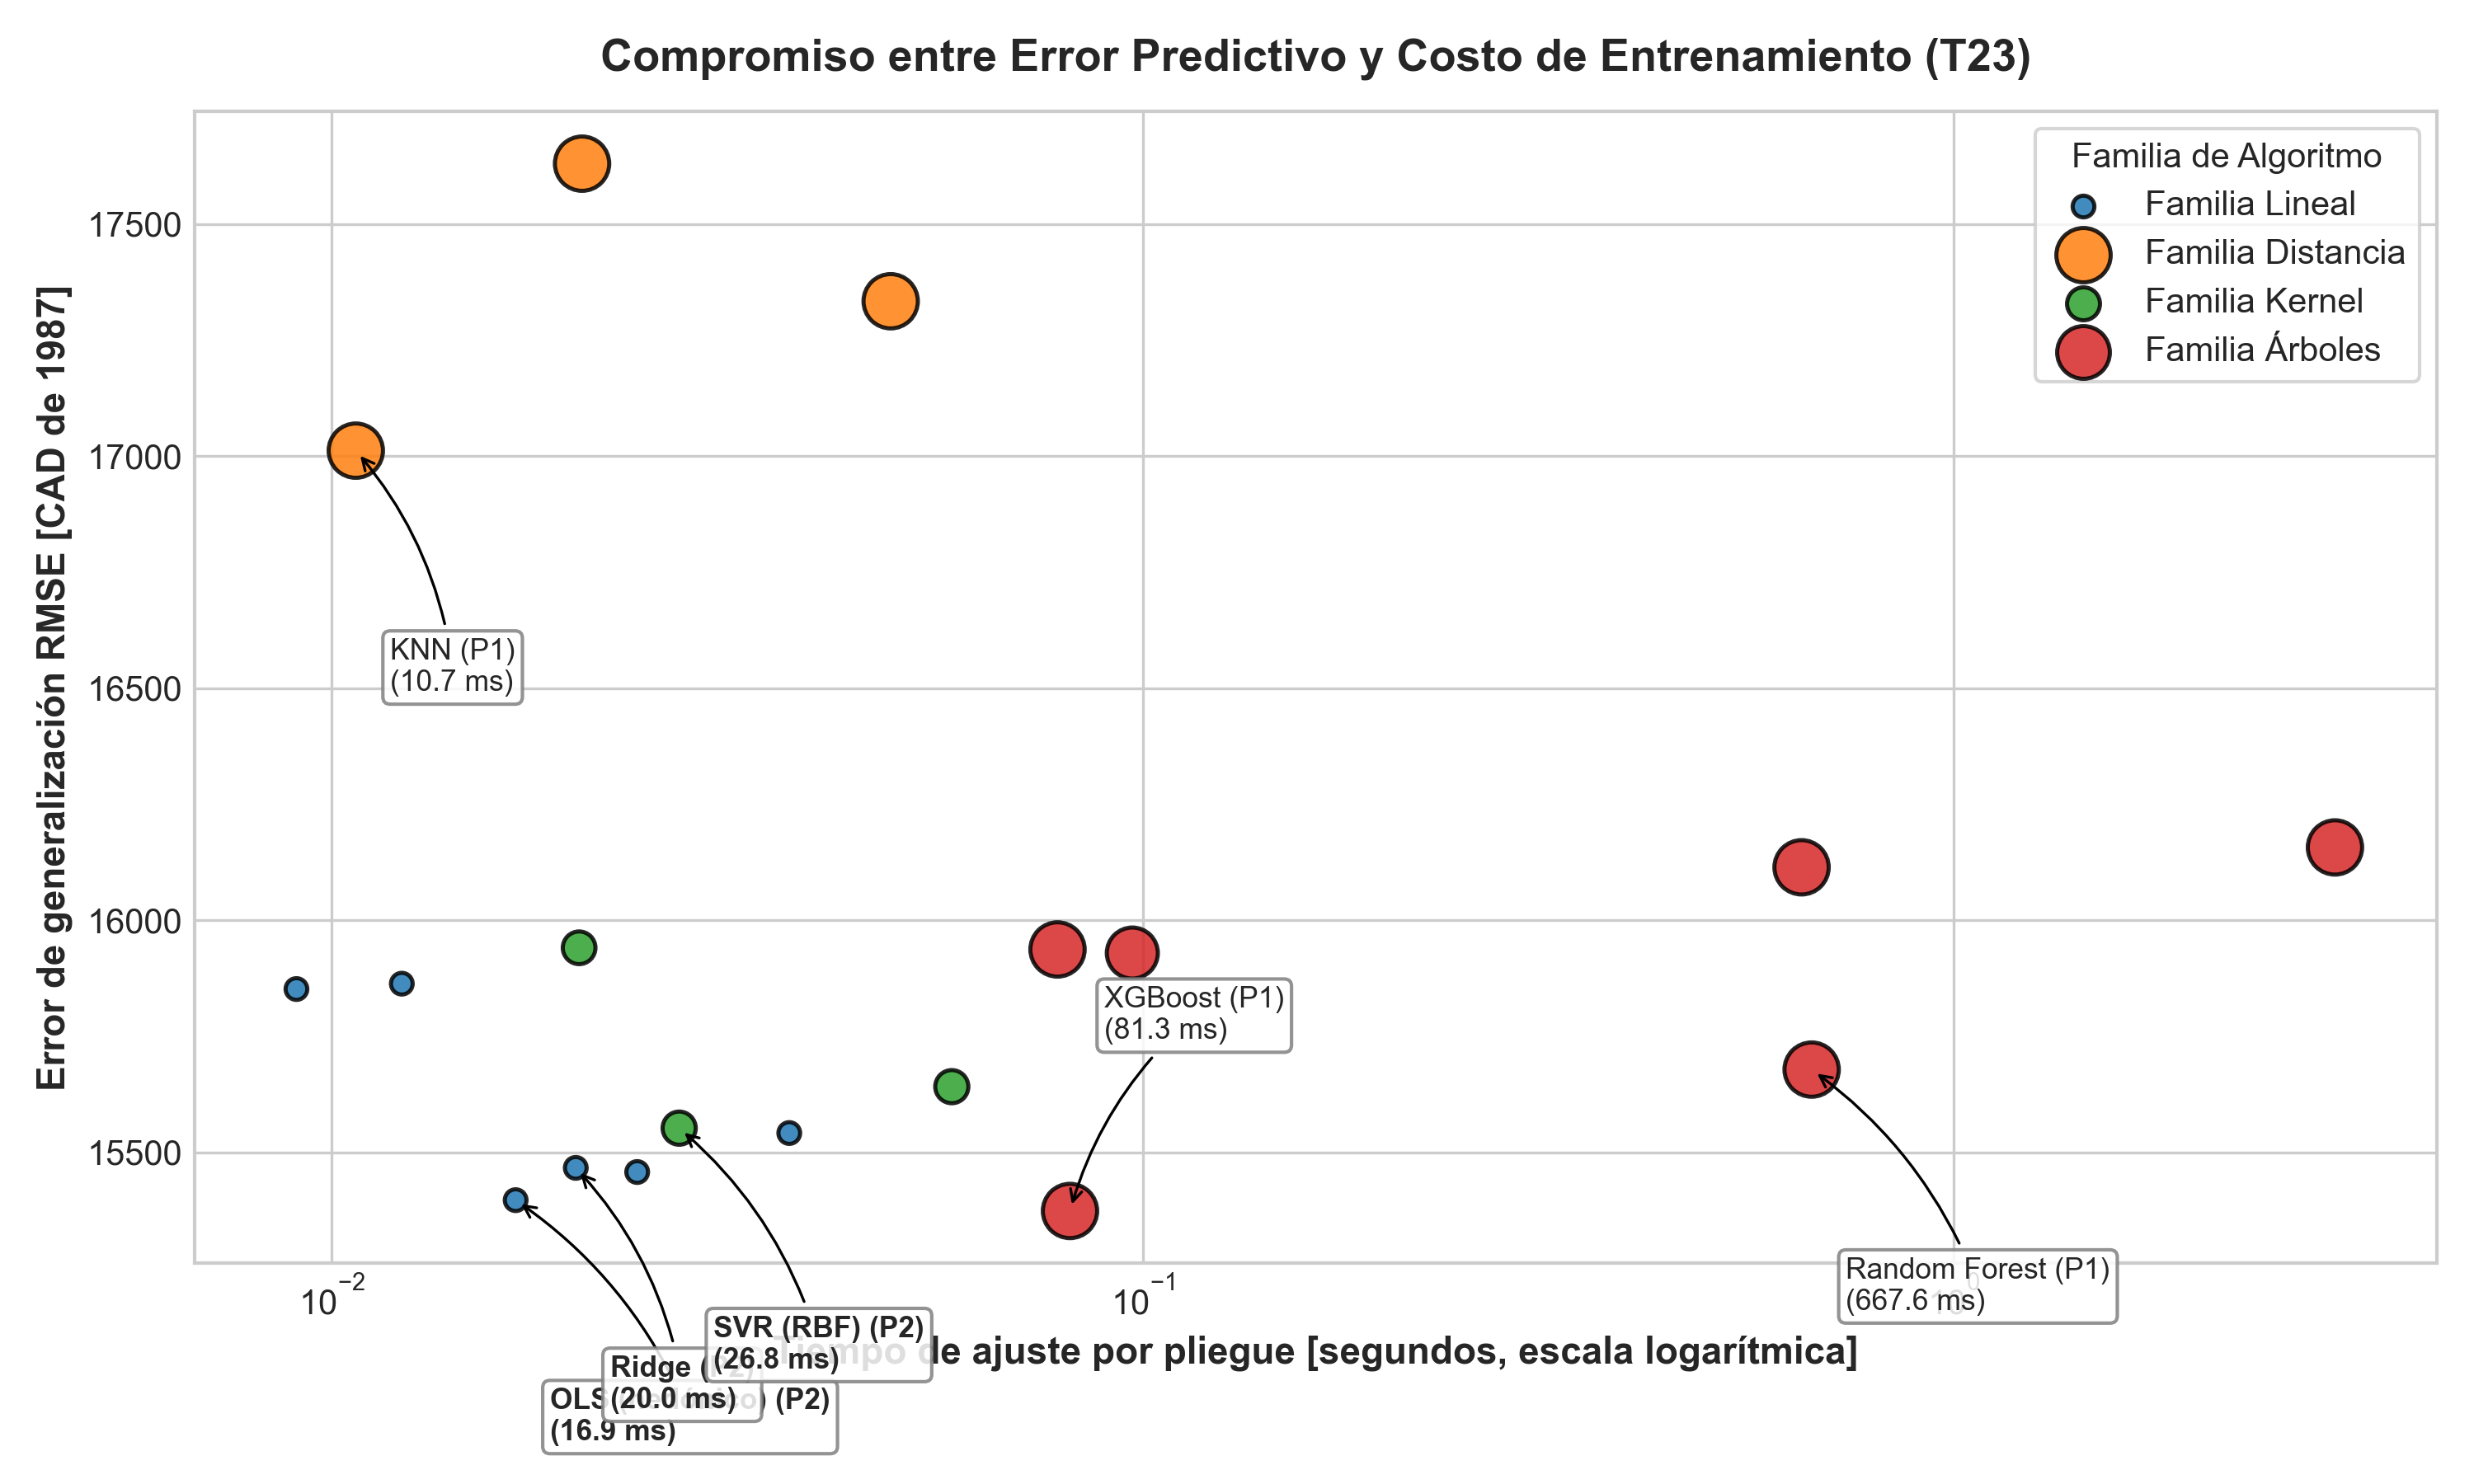

In [5]:
Image(str(DIR_FIGURAS / 'fig_t23_tradeoff_rmse_vs_tiempo_entrenamiento.png'))

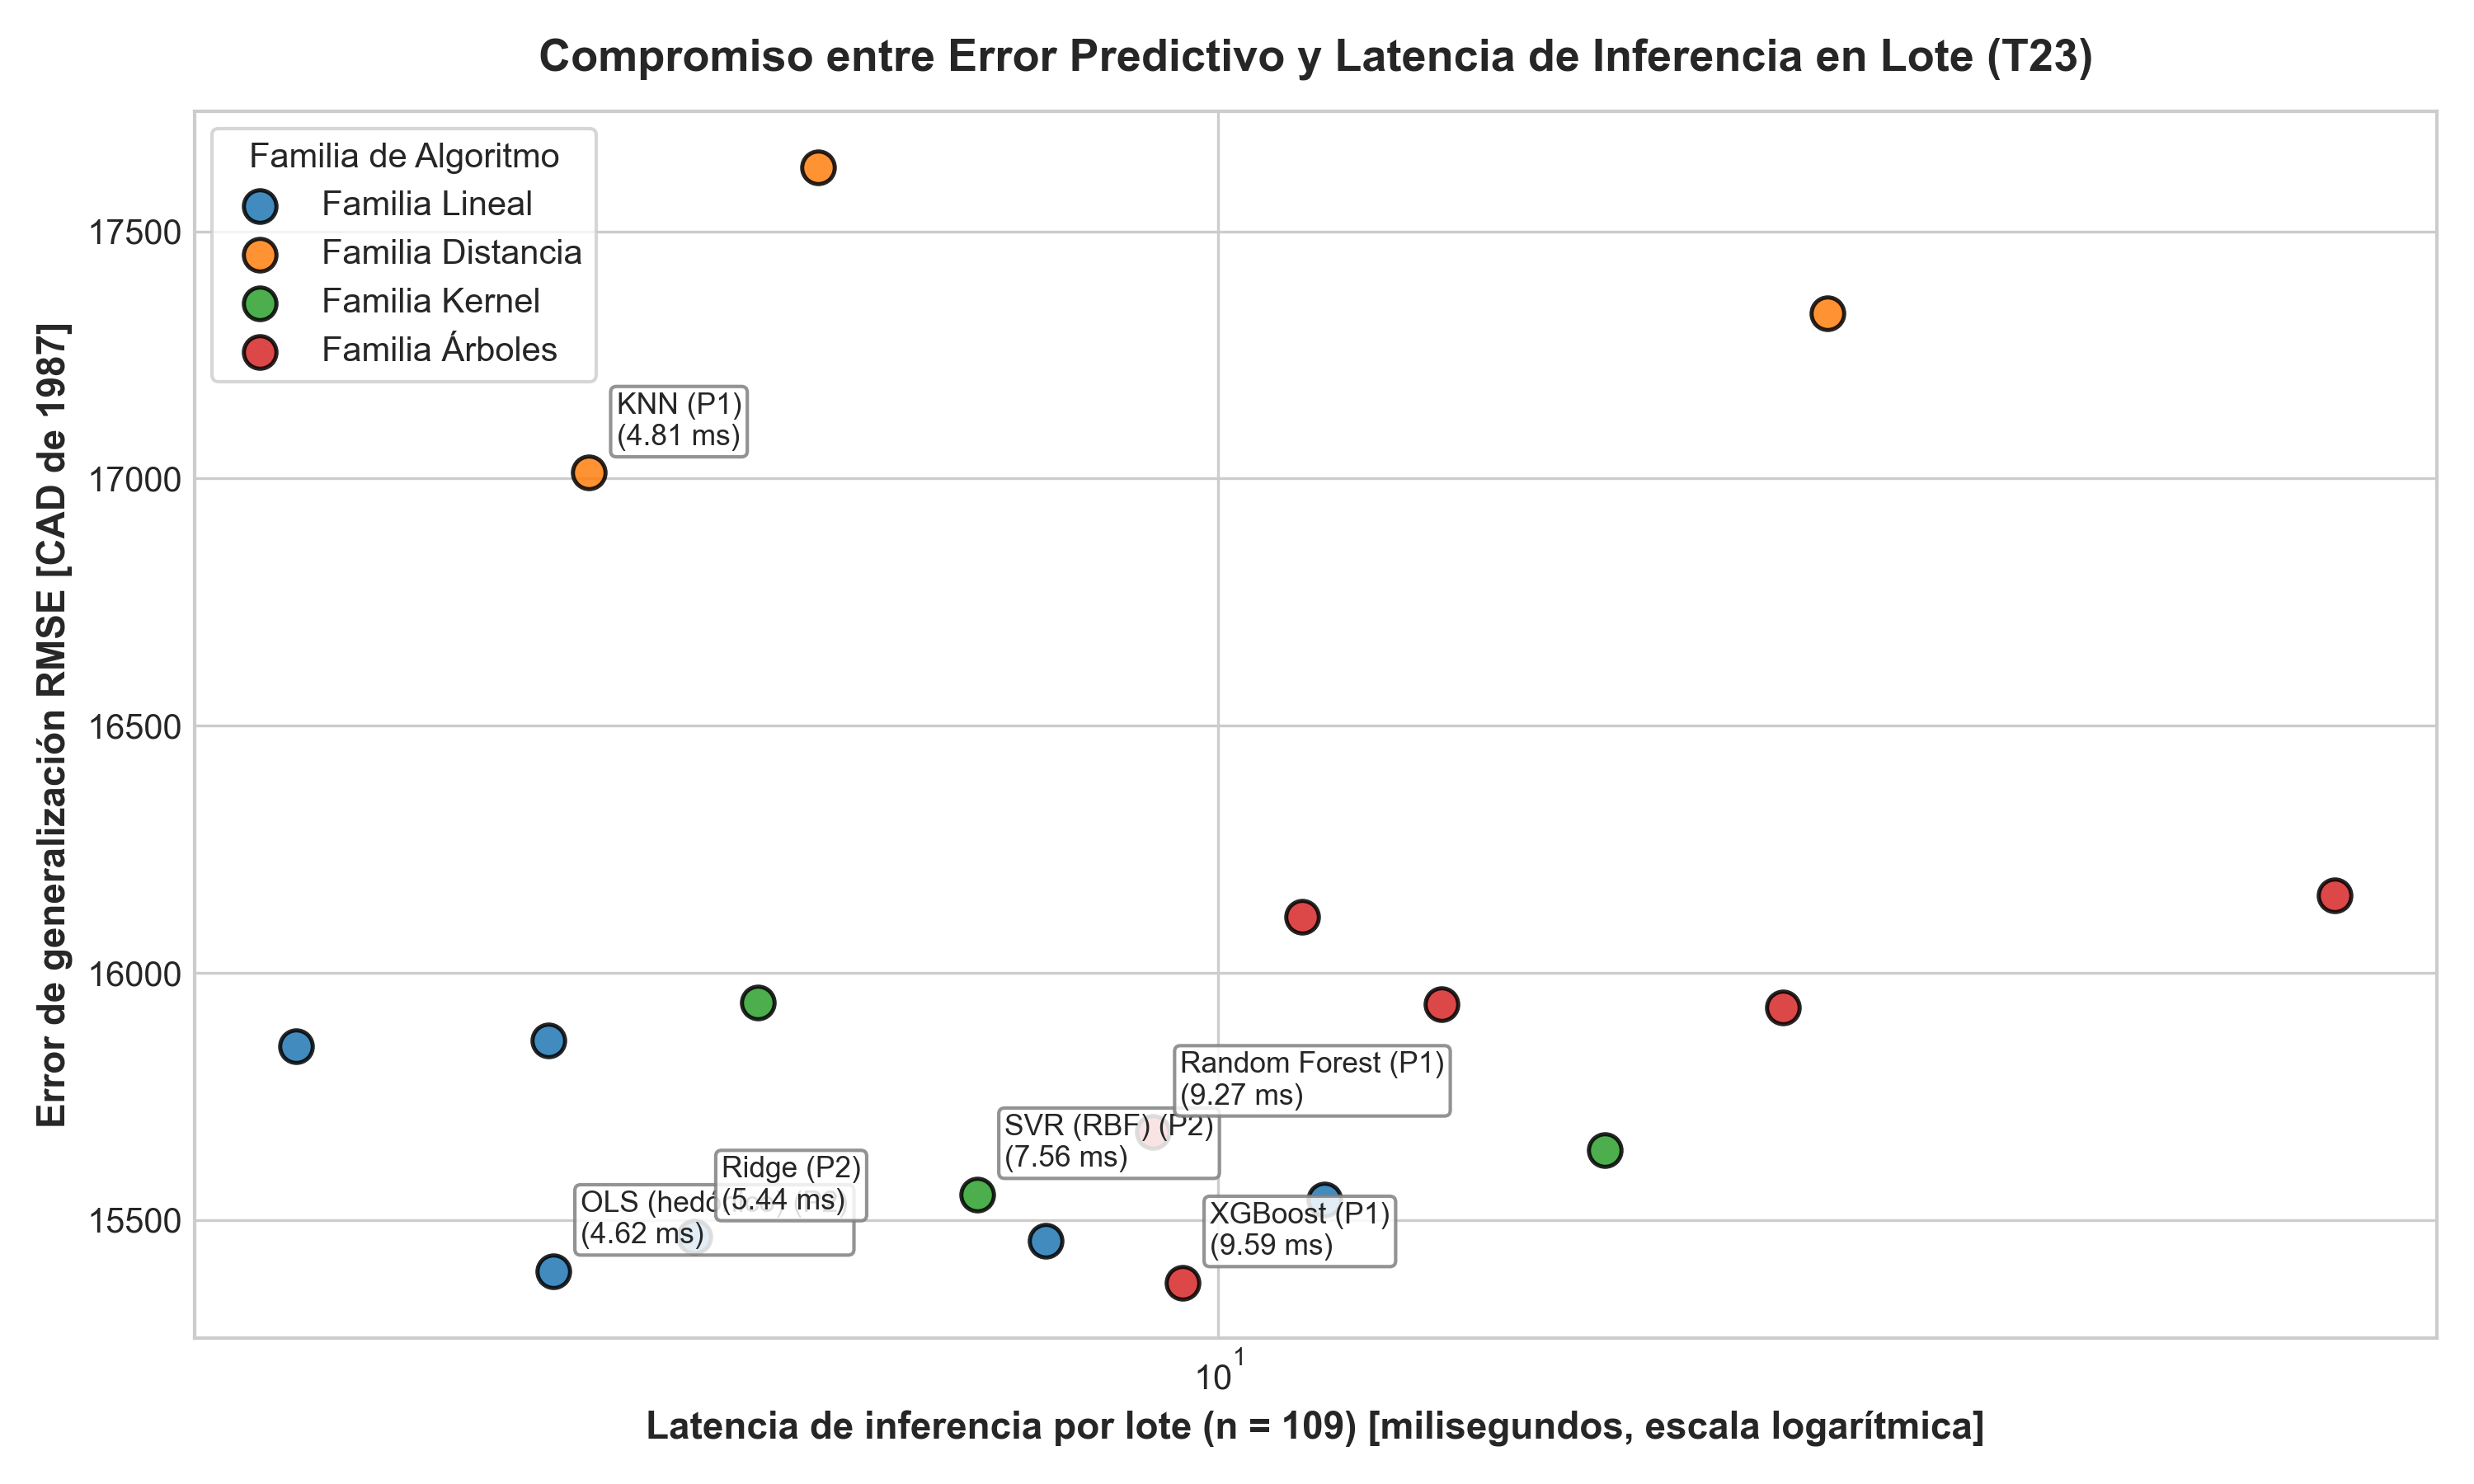

In [6]:
Image(str(DIR_FIGURAS / 'fig_t23_tradeoff_rmse_vs_latencia_inferencia.png'))

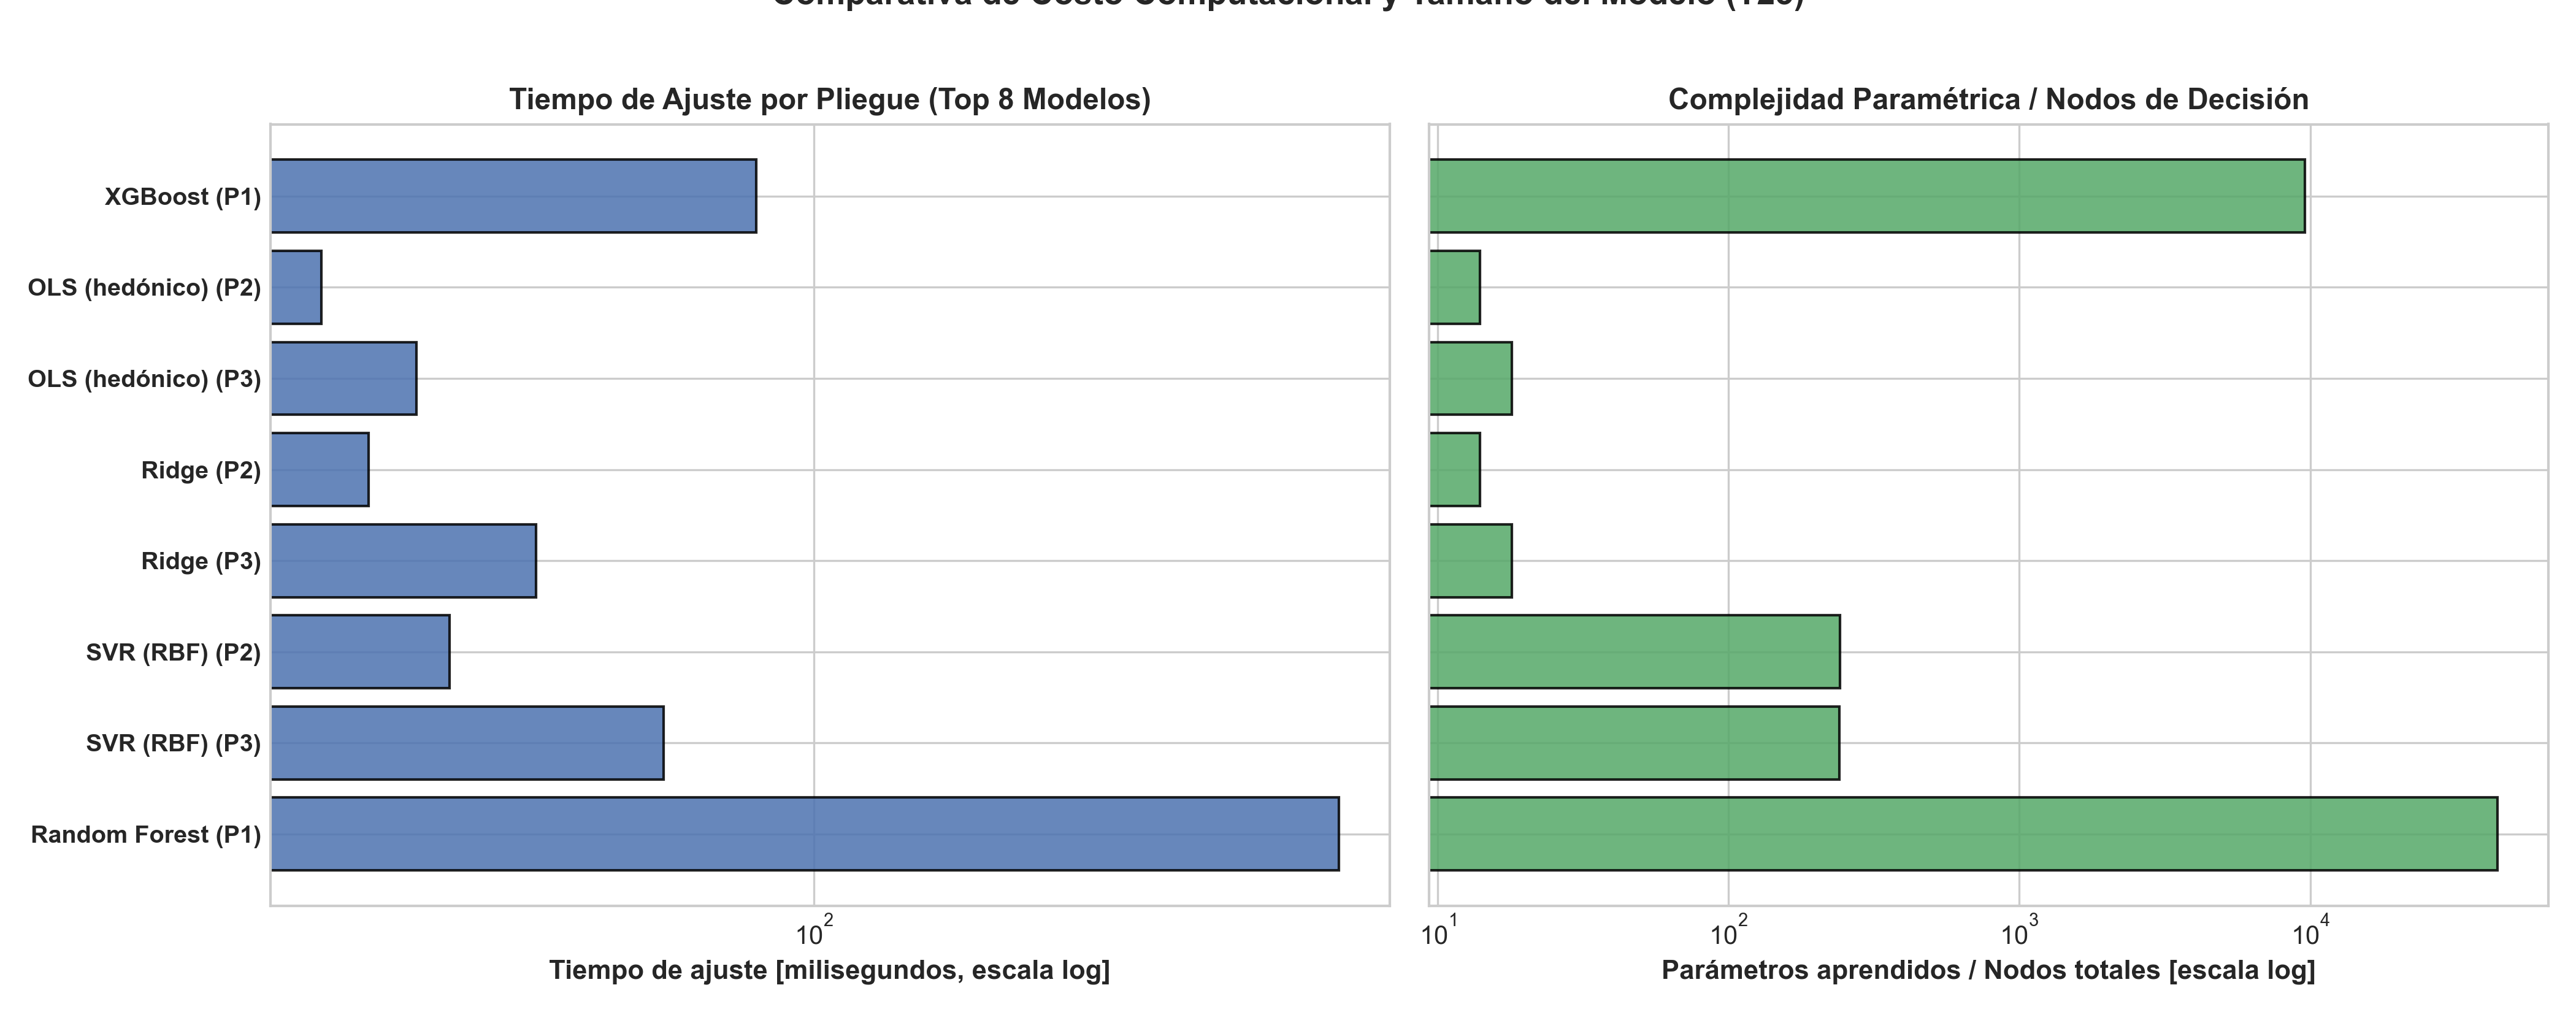

In [7]:
Image(str(DIR_FIGURAS / 'fig_t23_comparacion_recursos_modelos.png'))

## 6. Curvas de aprendizaje y escalabilidad frente al tamaño muestral $n$

Evaluamos cómo evolucionan el tiempo de entrenamiento y el error de validación cuando el tamaño de muestra de entrenamiento varía desde el 15% hasta el 100% de $n=436$. Esto permite diagnosticar si algún modelo sufre de sobreajuste por escasez de datos o si ha saturado su capacidad de aprendizaje.

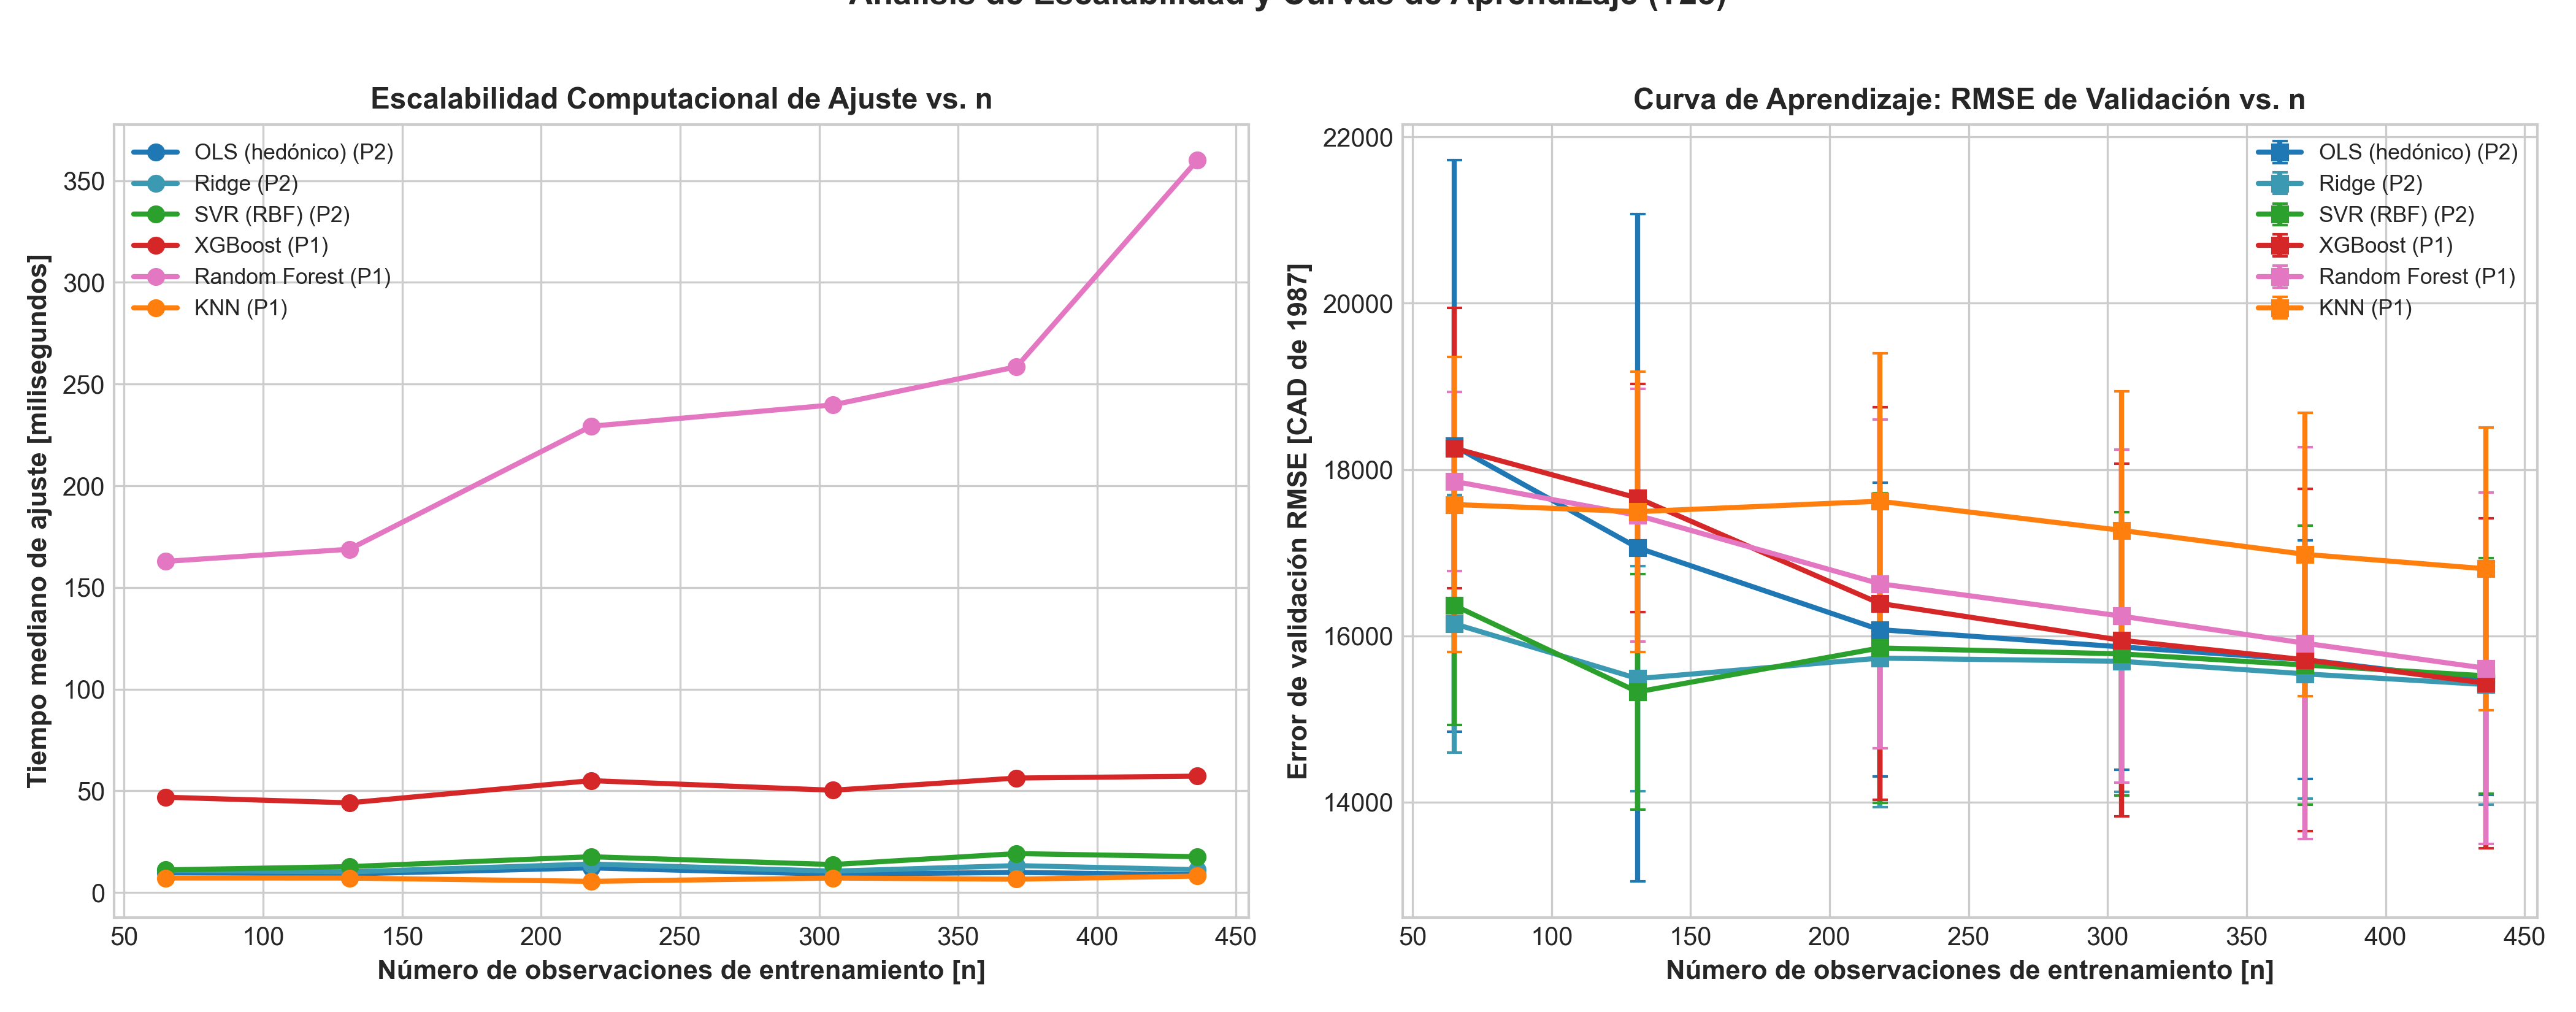

In [8]:
Image(str(DIR_FIGURAS / 'fig_t23_curvas_escalabilidad_n.png'))

In [9]:
df_esc = pd.read_csv(DIR_TABLAS / 't23_curvas_aprendizaje_escalabilidad.csv')
df_esc_resumen = df_esc.pivot(index='modelo_nombre', columns='n_observaciones', values='rmse_cad1987_media')
df_esc_resumen.round(2)

n_observaciones,65,131,218,305,371,436
modelo_nombre,,,,,,
KNN (P1),17579.31,17493.28,17618.73,17268.45,16980.02,16805.99
OLS (hedónico) (P2),18283.45,17058.64,16074.03,15866.06,15713.35,15453.21
Random Forest (P1),17858.09,17448.81,16626.64,16237.03,15910.83,15609.53
Ridge (P2),16144.60,15484.98,15731.33,15693.40,15542.04,15413.75
SVR (RBF) (P2),16365.44,15325.45,15853.63,15782.34,15648.80,15518.22
XGBoost (P1),18256.72,17657.14,16390.40,15946.09,15711.51,15430.20


## 7. Curvas de validación empíricas y diagnóstico del balance sesgo-varianza

Para complementar las curvas de escalabilidad frente a $n$, analizamos las **curvas de validación** evaluando el error de entrenamiento y de validación cruzada (5 pliegues) al variar la capacidad del modelo a través de hiperparámetros críticos:

1. **KNN ($k$ en $M3$ bajo $P2$):** Para $k=1$, el modelo memoriza el conjunto de entrenamiento ($RMSE_{train} = 0$), pero sufre sobreajuste y alta varianza en validación. Al aumentar $k$, el error de entrenamiento sube gradualmente y el de validación alcanza un mínimo óptimo en el rango $k \in [5, 11]$, balanceando sesgo y varianza antes de incurrir en subajuste para $k > 20$.
2. **SVR con kernel RBF ($C$ en $M4$ bajo $P1$):** Valores pequeños de $C < 1$ imponen una regularización severa (alto sesgo), mientras que valores de $C \ge 100$ permiten un ajuste flexible del margen que estabiliza el error de validación en torno a los \$15,900 CAD.
3. **XGBoost (profundidad del árbol `max_depth` en $M6$ bajo $P1$):** Para `max_depth = 1` (stumps), el modelo tiene alto sesgo. El error de validación se minimiza entre `max_depth = 3` y `4`. Para profundidades $\ge 6$, la brecha entre entrenamiento y validación se ensancha drásticamente, evidenciando sobreajuste por memorización de ruido local.


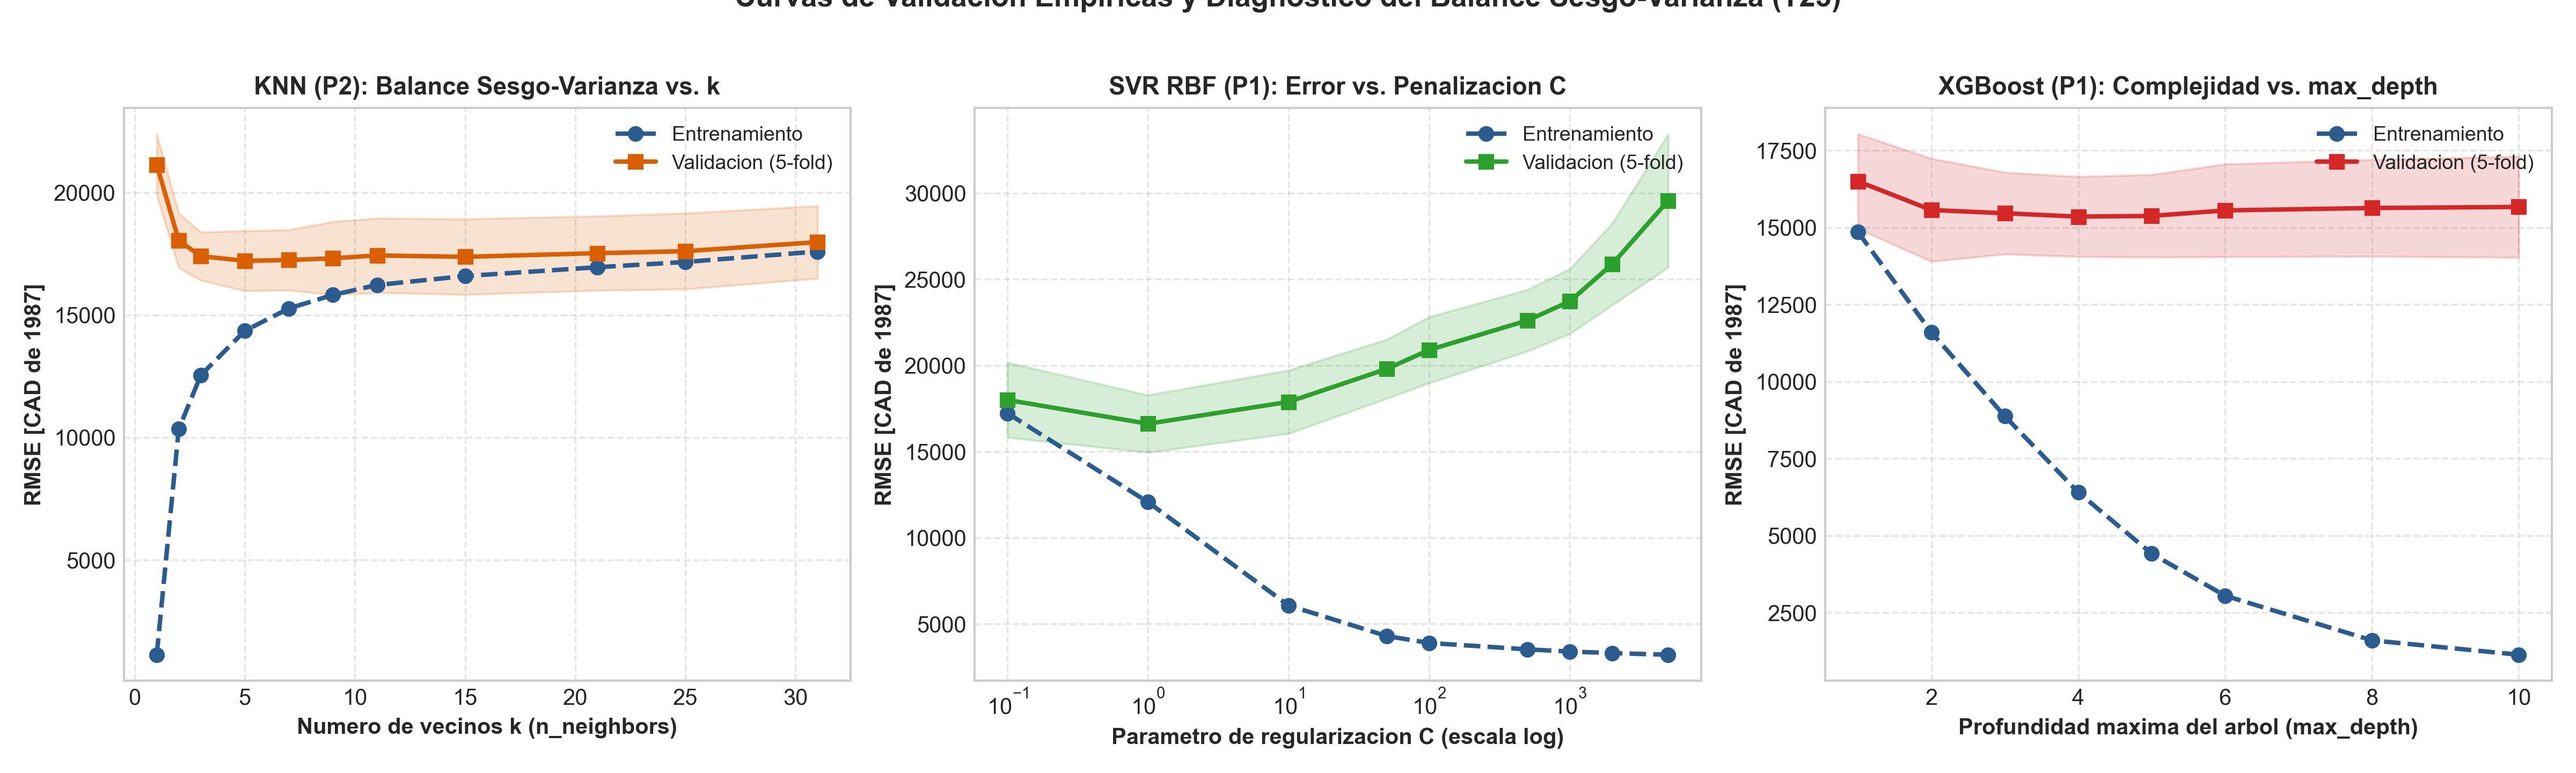

Muestra de las curvas de validación (resumen por hiperparámetro):


,modelo,pipeline,parametro,valor,rmse_train_cad,rmse_train_std,rmse_val_cad,rmse_val_std
0,KNN,KNN (P2),n_neighbors,1.0,1126.484500,332.805885,21136.344165,1258.261183
1,KNN,KNN (P2),n_neighbors,2.0,10344.989474,178.744060,18039.768819,1115.031344
2,KNN,KNN (P2),n_neighbors,3.0,12541.880621,305.705058,17404.020619,984.326863
11,SVR,SVR (RBF) (P1),C,0.1,17230.112347,363.954357,17994.747495,2174.576081
12,SVR,SVR (RBF) (P1),C,1.0,12065.097853,388.344446,16613.698358,1663.350446
13,SVR,SVR (RBF) (P1),C,10.0,6064.604652,383.540715,17882.595335,1839.491706
20,XGBoost,XGBoost (P1),max_depth,1.0,14855.120911,368.661473,16501.767808,1537.664755
21,XGBoost,XGBoost (P1),max_depth,2.0,11595.313760,151.275544,15569.748680,1670.613669
22,XGBoost,XGBoost (P1),max_depth,3.0,8875.142820,141.179643,15464.432468,1327.363870


In [10]:
# Visualización de las curvas de validación empíricas generadas por ejecutar_t23.py
ruta_fig_val = DIR_FIGURAS / "fig_t23_curvas_validacion.png"
display(Image(filename=str(ruta_fig_val)))

df_val = pd.read_csv(DIR_TABLAS / "t23_curvas_validacion.csv")
print("Muestra de las curvas de validación (resumen por hiperparámetro):")
display(df_val.groupby("modelo").head(3))


## 8. Conclusiones de T23 y Criterios de Parsimonia para T25

1. **Disparidad Radical de Costo Temporal frente a Empate Predictivo:**
   - En T22 se demostró un empate estadístico indiscutible entre **OLS Hedónico (P2)** ($15,397$ CAD), **Ridge (P2)** ($15,467$ CAD), **SVR (RBF) (P2)** ($15,552$ CAD), **XGBoost (P1)** ($15,587$ CAD) y **Random Forest (P1)** ($15,678$ CAD).
   - Sin embargo, empíricamente **OLS Hedónico (P2)** se ajusta en **83.3 ms**, mientras que **Random Forest (P1)** requiere **1,254 ms** ($15\times$ más lento) y **Random Forest (P3)** tarda **3,340 ms** ($40\times$ más lento). En inferencia por lote, OLS tarda **5.76 ms** frente a **14.83 ms** en Random Forest.

2. **Sobrecarga Estructural y Huella de Memoria (Navaja de Ockham):**
   - El modelo lineal OLS/Ridge sólo aprende **14 parámetros escalares** (13 coeficientes + 1 intercepto) con un tamaño serializado en disco de **2.3 KB**.
   - En contraste, Random Forest construye **44,048 nodos de decisión** repartidos en 200 árboles, ocupando **774.5 KB** en disco ($335\times$ más memoria). XGBoost genera **9,724 nodos** y pesa **126 KB** ($55\times$ más).

3. **Diagnóstico de Escalabilidad:**
   - Las curvas de aprendizaje demuestran que OLS Hedónico y Ridge alcanzan su asíntota de error de generalización de forma temprana ($n \approx 200$), exhibiendo una varianza muestral sumamente estable.
   - Por el contrario, los ensambles no lineales requieren mayor volumen de datos para estabilizar sus fronteras de decisión y presentan una pendiente de costo temporal significativamente mayor sin aportar mejoras en el error cuadrático medio.

4. **Veredicto para la Selección del Modelo en T25:**
   - Aplicando el **Principio de Parsimonia**, si un modelo lineal de 14 parámetros empata y supera ligeramente a un ensamble de 44,000 nodos, la elección científicamente justificada para el avalúo masivo es el **modelo lineal hedónico (OLS / Ridge con preprocesamiento P2)**, maximizando la interpretabilidad económica, minimizando la latencia operativa y eliminando el riesgo de sobreajuste estructural.